In [1]:
library(tidyverse)
library(GenomicRanges)
library(gridExtra)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:lubridate’:

    intersect, setdiff, union


The following objects are masked from ‘package:dplyr’:

    combine, intersect, setdiff, union


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, 

In [ ]:
sessionInfo()

In [3]:
theme_set(theme_bw() + theme(rect=element_rect(linewidth=1), text=element_text(size=15), panel.grid=element_blank()))

In [4]:
bed_to_gr <- function(filename){
    temp <- read.delim(filename, header=F, sep='\t')
    gr <- GRanges(seqnames=temp$V1, ranges=IRanges(start=temp$V2, end=temp$V3))
    return(gr)
}

In [13]:
#making GR for ATAC-seq peaks
control <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/bed/ATAC_peaks/H1/consensus/H1_DMSO_replicated.bed")
acbi1 <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/bed/ATAC_peaks/H1/consensus/H1_ACBI1_replicated.bed")
a4kd <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/bed/ATAC_peaks/H1/consensus/H1_A4-KD_replicated.bed")

consensus <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/bed/ATAC_peaks/H1/consensus/H1_consensus_indexed.bed")


In [14]:
#making GR from TSS, histone mod & CTCF peaks
TSS <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/GENCODE/gencode.v47.annotation.transcripts_tss.1kb.bed")
H3K4me3 <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/bed/ENCODE_cRE_definition/H1/H3K4me3.bed")
H3K4me1 <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/bed/ENCODE_cRE_definition/H1/H3K4me1.bed")
H3K27ac <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/bed/ENCODE_cRE_definition/H1/H3K27ac.bed")
H3K27me3 <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/bed/ENCODE_cRE_definition/H1/H3K27me3.bed")
CTCF <- bed_to_gr("~/projects/poised_enh_manuscript/inputs/bed/ENCODE_cRE_definition/H1/CTCF.bed")

In [15]:
#defining cRE types based on TSS, histone mod, and CTCF overlaps

#which peaks overlap with TSS or other chromatin features
consensus$TSS <- ifelse(countOverlaps(consensus,TSS)>0, TRUE, FALSE)
consensus$H3K4me3 <- ifelse(countOverlaps(consensus,H3K4me3)>0, TRUE, FALSE)
consensus$H3K4me1 <- ifelse(countOverlaps(consensus,H3K4me1)>0, TRUE, FALSE)
consensus$H3K27ac <- ifelse(countOverlaps(consensus,H3K27ac)>0, TRUE, FALSE)
consensus$H3K27me3 <- ifelse(countOverlaps(consensus,H3K27me3)>0, TRUE, FALSE)
consensus$CTCF <- ifelse(countOverlaps(consensus,CTCF)>0, TRUE, FALSE)

#define type based on combinations of the above
consensus$type <- case_when(
    consensus$TSS==T & consensus$H3K4me3 ==T ~ "prom", #promoter: TSS-proximal and H3K4me3 overlapping
    consensus$TSS==T & consensus$H3K4me3 ==F ~ "other_TSS", #all other (non-H3K4me3) TSS-proximal elements
    consensus$TSS==F & consensus$H3K4me1 ==T & consensus$H3K27ac==T ~ "active_enh", #active enhancer: TSS-distal, H3K4me1 and H3K27ac overlapping
    consensus$TSS==F & consensus$H3K4me1 ==T & consensus$H3K27ac==F & consensus$H3K27me3==F ~ "poised_enh", #poised enhancer: TSS-distal, H3K4me1+ and H3K27 unmodified
    consensus$TSS==F & consensus$H3K4me1 ==T & consensus$H3K27ac==F & consensus$H3K27me3==T ~ "poised_enh_H3K27me3", #'poised' enhancers that are H3K27me3+
    consensus$TSS==F & consensus$H3K4me1 ==F & consensus$CTCF==T ~ "CTCF_only", #TSS-distal, H3K4me1- elements with CTCF binding
    consensus$TSS==F & consensus$H3K4me1 ==F & consensus$CTCF==F ~ "other_nonTSS") #all other TSS-distal, H3K4me1- elements




In [16]:
#write table with peak coordiantes and overlap/type metadata
write.table(data.frame(consensus), "~/projects/poised_enh_manuscript/inputs/bed/ATAC_peaks/H1/consensus/H1_consensus_annot.tsv", quote=FALSE, sep='\t', row.names=FALSE)

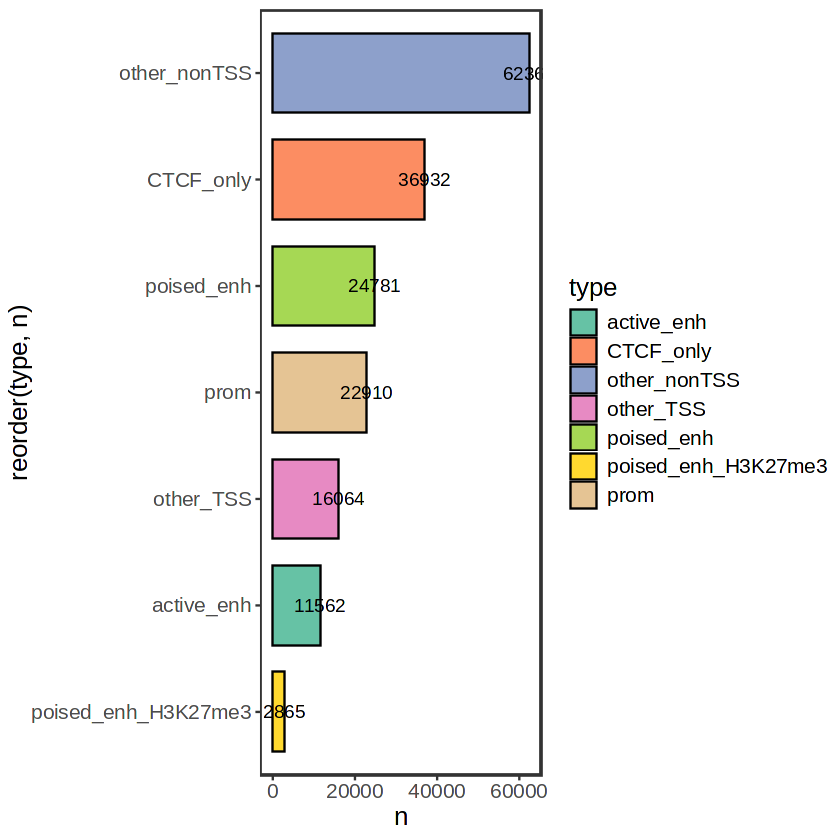

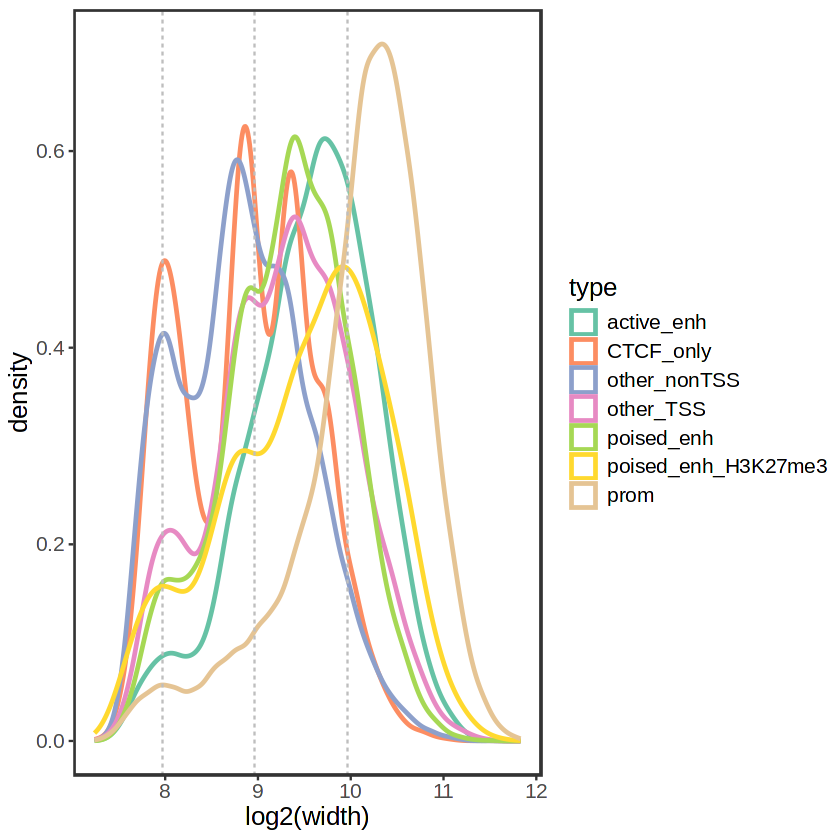

In [11]:
#look at # of cREs by type
consensus %>% data.frame() %>% group_by(type) %>% summarize(n = n()) %>% 
    ggplot(aes(y=reorder(type,n),x=n, fill=type)) + geom_col(color="black", width=.75) + geom_text(aes(label=n)) + 
    scale_fill_brewer(palette="Set2")

consensus %>% data.frame()  %>% 
    ggplot(aes(x=log2(width), color=type)) + geom_density(linewidth=1) + 
    geom_vline(xintercept=log2(c(250, 500, 1000)), linetype=2, color="grey") + 
    scale_color_brewer(palette="Set2")

In [50]:
#read in counts matrix
cm <- read.delim("~/projects/poised_enh_manuscript/inputs/countmat/H1/H1_consensus_indexed_counts.tsv", sep='\t', header=F)
cm <- cm %>% mutate(inDMSO=ifelse(countOverlaps(consensus,control)>0, TRUE, FALSE), 
                    inACBI1=ifelse(countOverlaps(consensus,acbi1)>0, TRUE, FALSE),
                    inA4K2=ifelse(countOverlaps(consensus,a4kd)>0,TRUE,FALSE),
                    dmso_avg=rowMeans(cm[,5:6]), 
                    brm_avg=rowMeans(cm[,7:8]))

consensus_counts <- GRanges(seqnames=cm$V1, ranges=IRanges(start=cm$V2,end=cm$V3), mcols=cm[,14:18])

[1]  TRUE  TRUE  TRUE  TRUE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE
   [13]  TRUE  TRUE  TRUE  TRUE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE
   [25]  TRUE  TRUE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE
   [37]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE  TRUE  TRUE FALSE  TRUE  TRUE
   [49] FALSE  TRUE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE  TRUE FALSE FALSE
   [61]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE
   [73]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE
   [85]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE
   [97]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE
  [109]  TRUE FALSE FALSE  TRUE  TRUE  TRUE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE
  [121]  TRUE  TRUE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE
  [133]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE  TRUE  TRUE
  [145]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE  TRUE FALSE  TRUE FALSE  TRUE
  [157] FALSE  TRUE  TRUE FALSE  TRUE  TRUE  TRUE FALSE  TRUE FALSE  TRUE  TRUE
  [169] FALSE  TRUE  TRUE FALSE  TRUE  TRUE  TRUE FALSE FALSE  TRUE  TRUE FALSE
  [181]  TRUE  TRUE  TRUE  TRUE FALSE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE
  [193]  TRUE  TRUE  TRUE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE  TRUE
  [205]  TRUE  TRUE  TRUE FALSE FALSE FALSE  TRUE FALSE  TRUE  TRUE  TRUE  TRUE
  [217] FALSE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE  TRUE  TRUE FALSE  TRUE
  [229]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE  TRUE  TRUE  TRUE FALSE  TRUE
  [241]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE
  [253] FALSE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE  TRUE FALSE  TRUE
  [265]  TRUE  TRUE FALSE  TRUE FALSE FALSE  TRUE  TRUE  TRUE FALSE FALSE  TRUE
  [277]  TRUE FALSE FALSE FALSE  TRUE FALSE  TRUE  TRUE FALSE  TRUE FALSE  TRUE
  [289]  TRUE  TRUE  TRUE  TRUE FALSE  TRUE FALSE  TRUE  TRUE  TRUE  TRUE FALSE
  [301]  TRUE FALSE  TRUE  TRUE FALSE  TRUE FALSE  TRUE FALSE  TRUE FALSE  TRUE
  [313]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE
  [325]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE
  [337]  TRUE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE
  [349]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE FALSE  TRUE  TRUE  TRUE
  [361]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE FALSE  TRUE  TRUE  TRUE  TRUE
  [373]  TRUE  TRUE  TRUE FALSE  TRUE FALSE FALSE  TRUE  TRUE  TRUE  TRUE FALSE
  [385] FALSE  TRUE FALSE  TRUE FALSE  TRUE  TRUE FALSE  TRUE FALSE FALSE  TRUE
  [397]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE
  [409]  TRUE  TRUE FALSE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE  TRUE  TRUE
  [421]  TRUE  TRUE  TRUE  TRUE FALSE  TRUE  TRUE FALSE  TRUE FALSE FALSE  TRUE
  [433]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE  TRUE  TRUE  TRUE
  [445]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE  TRUE FALSE
  [457]  TRUE  TRUE FALSE  TRUE  TRUE  TRUE FALSE  TRUE  TRUE  TRUE FALSE  TRUE
  [469]  TRUE FALSE  TRUE FALSE  TRUE  TRUE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE
  [481] FALSE  TRUE  TRUE  TRUE  TRUE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE
  [493]  TRUE  TRUE FALSE  TRUE  TRUE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE
  [505]  TRUE  TRUE  TRUE  TRUE  TRUE FALSE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE
  [517]  TRUE  TRUE  TRUE  TRUE  TRUE FALSE  TRUE  TRUE  TRUE FALSE  TRUE  TRUE
  [529]  TRUE  TRUE FALSE  TRUE FALSE  TRUE  TRUE  TRUE  TRUE FALSE  TRUE  TRUE
  [541]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE
  [553]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE
  [565] FALSE  TRUE FALSE  TRUE  TRUE  TRUE  TRUE FALSE  TRUE  TRUE  TRUE FALSE
  [577]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE
  [589]  TRUE  TRUE  TRUE  TRUE FALSE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE
  [6

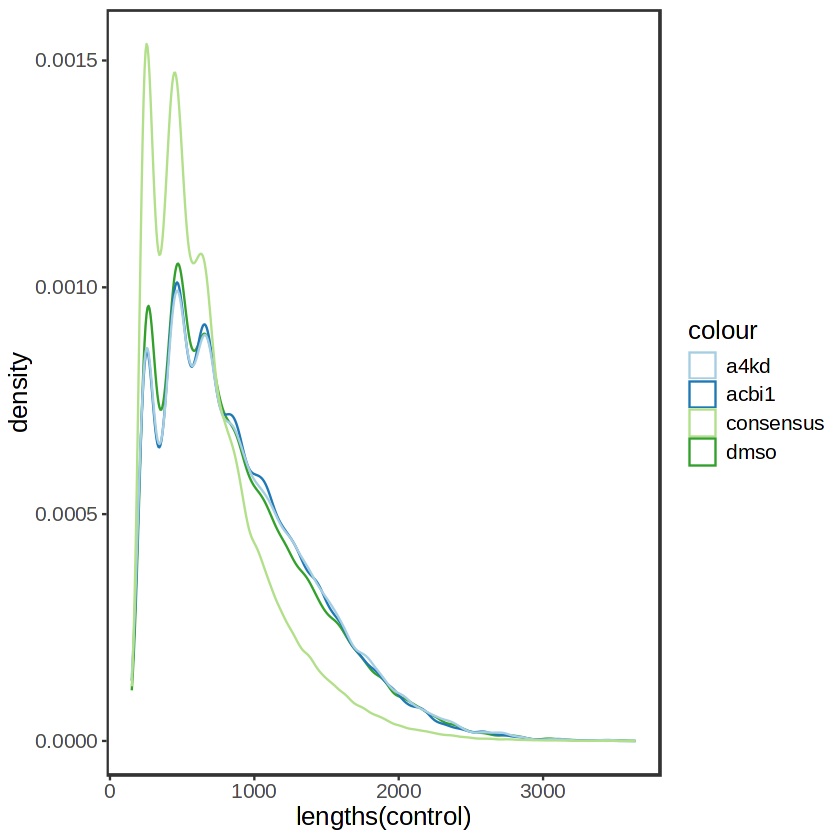

In [26]:
#Comparing peak size distributions
p1 <- ggplot() +
    geom_density(aes(color="dmso",x=lengths(control))) +
    geom_density(aes(color="acbi1",x=lengths(acbi1))) +
    geom_density(aes(color="a4kd",x=lengths(a4kd))) +
    geom_density(aes(color="consensus",x=lengths(consensus))) +
    scale_color_brewer(palette="Paired")

p1

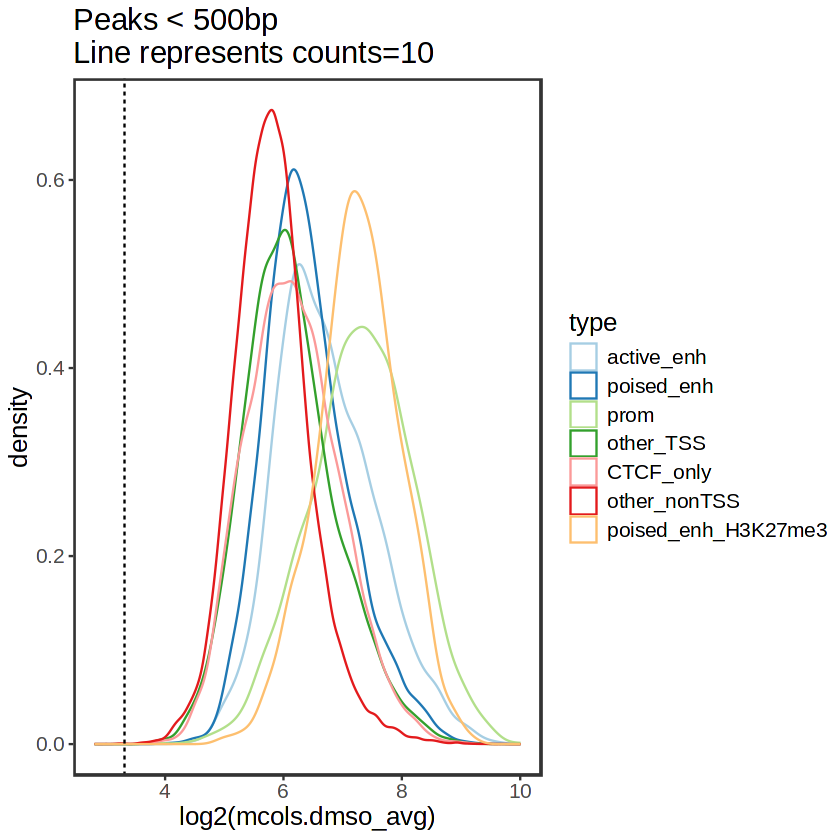

`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.
Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”
`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.


type,pct
<chr>,<dbl>
CTCF_only,100.00000000
active_enh,100.00000000
other_TSS,100.00000000
other_nonTSS,0.01122406
other_nonTSS,99.98877594
poised_enh,100.00000000
poised_enh_H3K27me3,100.00000000
prom,100.00000000


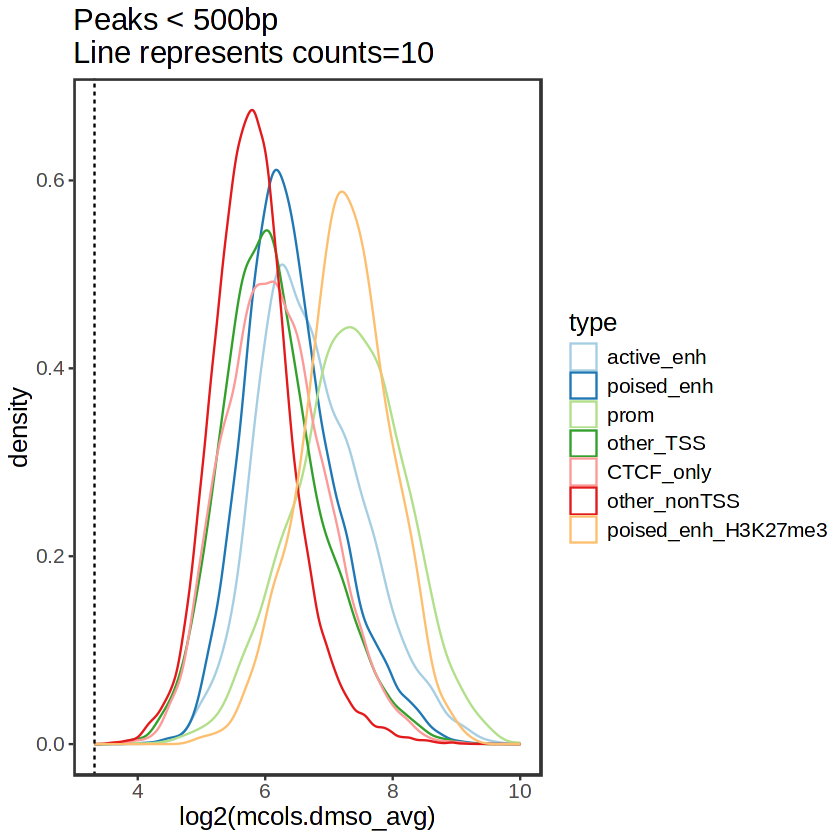

In [51]:
#plot counts by cRE type before and after filtering
data.frame(consensus_counts) %>% mutate(type=consensus$type, CTCF=consensus$CTCF) %>% filter(width < 500) %>% 
    ggplot(aes(x=log2(mcols.dmso_avg), color=factor(type, levels=c("active_enh", "poised_enh", "prom", "other_TSS", "CTCF_only", "other_nonTSS", "poised_enh_H3K27me3")))) + 
    geom_density() + geom_vline(xintercept=log2(10), linetype=2) + scale_color_brewer(palette="Paired", name="type") + 
    ggtitle("Peaks < 500bp\nLine represents counts=10")

data.frame(consensus_counts) %>% mutate(type=consensus$type, CTCF=consensus$CTCF) %>% filter(width < 500, mcols.dmso_avg > 10) %>% 
    ggplot(aes(x=log2(mcols.dmso_avg), color=factor(type, levels=c("active_enh", "poised_enh", "prom", "other_TSS", "CTCF_only", "other_nonTSS", "poised_enh_H3K27me3")))) + 
    geom_density() + geom_vline(xintercept=log2(10), linetype=2) + scale_color_brewer(palette="Paired", name="type") + 
    ggtitle("Peaks < 500bp\nLine represents counts=10")

#what % of peaks is filtered out by this threshold (by category)
data.frame(consensus_counts) %>% mutate(type=consensus$type) %>% group_by(type, mcols.dmso_avg > 10) %>% summarize(n=n(), width=median(width), counts=median(mcols.dmso_avg)) %>% ungroup() %>% group_by(type) %>% summarize(pct=100*n/sum(n))

In [38]:
filt <- which(consensus_counts$mcols.dmso_avg <= 10)

In [39]:
consensus[-filt,]

GRanges object with 177081 ranges and 7 metadata columns:
           seqnames            ranges strand |       TSS   H3K4me3   H3K4me1
              <Rle>         <IRanges>  <Rle> | <logical> <logical> <logical>
       [1]     chr1     778366-779299      * |      TRUE      TRUE     FALSE
       [2]     chr1     797430-797966      * |     FALSE     FALSE     FALSE
       [3]     chr1     804756-805016      * |     FALSE     FALSE     FALSE
       [4]     chr1     817333-818369      * |      TRUE     FALSE     FALSE
       [5]     chr1     818971-819172      * |     FALSE     FALSE     FALSE
       ...      ...               ...    ... .       ...       ...       ...
  [177077]     chrY 19549914-19550716      * |     FALSE      TRUE      TRUE
  [177078]     chrY 19566912-19568176      * |      TRUE      TRUE     FALSE
  [177079]     chrY 19744345-19745287      * |      TRUE      TRUE     FALSE
  [177080]     chrY 20575442-20576230      * |      TRUE      TRUE     FALSE
  [177081]     chr

In [71]:
#write out table of annotated peaks
consensus_filt <- data.frame(consensus[-filt,], "inDMSO"=consensus_counts$mcols.inDMSO[-filt], "inACBI1"=consensus_counts$mcols.inACBI1[-filt],"inACBI1"=consensus_counts$mcols.inA4K2[-filt]) %>% mutate(ID=seq(1,nrow(cm[-filt,])))
write.table(consensus_filt, "H1_consensus_filt_annot.tsv", row.names=F, quote=F, sep='\t')
#also write out BED-formatted and indexed peak list
consensus_filt_bed <- consensus_filt %>% select(seqnames, start, end) %>% mutate(ID=seq(1,nrow(consensus_filt))) %>% `colnames<-`(NULL)
write.table(consensus_filt_bed, "H1_consensus_filt.bed", row.names=F, quote=F, sep='\t')
#write out filtered counts matrix
write.table(cm[-filt,1:13],"~/projects/poised_enh_manuscript/inputs/countmat/H1/H1_consensus_filt.tsv", sep='\t',col.names=F, row.names=F, quote=FALSE)